# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()


(891, 12)


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba,odsetek_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


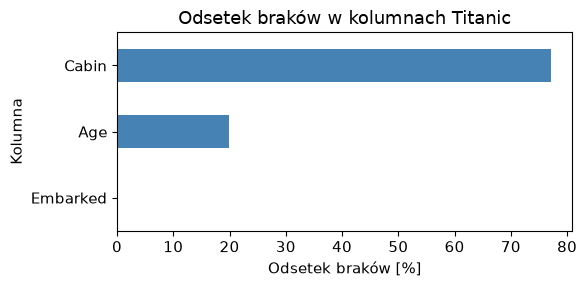

In [4]:
# 1. Liczba i odsetek braków posortowane malejąco
braki = titanic.isna().sum()
odsetek = (titanic.isna().mean() * 100).round(2)
tabela_brakow = pd.DataFrame({'liczba': braki, 'odsetek_%': odsetek})
tabela_brakow = tabela_brakow[tabela_brakow['liczba'] > 0].sort_values('liczba', ascending=False)
display(tabela_brakow)

# 2. Poziomy wykres słupkowy
plt.figure(figsize=(6, 3))
tabela_brakow['odsetek_%'].sort_values().plot.barh(color='steelblue')
plt.title("Odsetek braków w kolumnach Titanic")
plt.xlabel("Odsetek braków [%]")
plt.ylabel("Kolumna")
plt.tight_layout()
plt.show()


### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

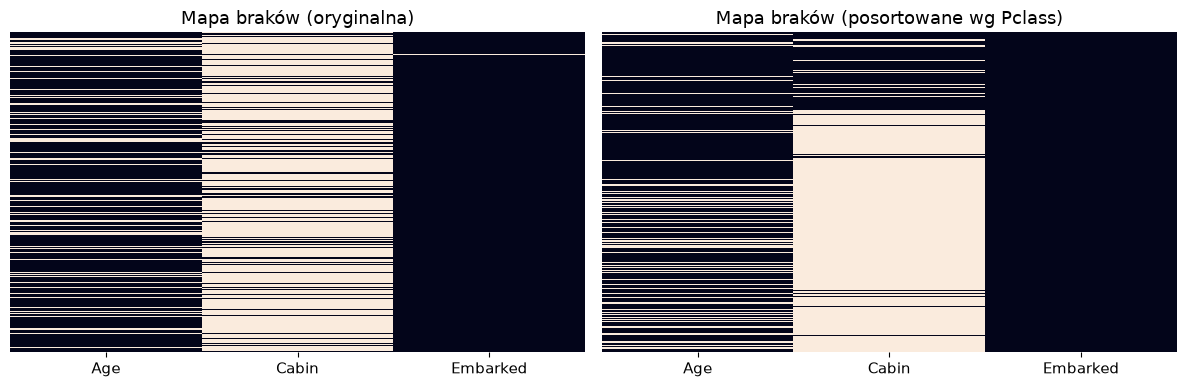

In [6]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Oryginalna kolejność
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=axes[0], yticklabels=False)
axes[0].set_title("Mapa braków (oryginalna)")

# Posortowane według Pclass
sns.heatmap(titanic.sort_values('Pclass')[kolumny].isna(), cbar=False, ax=axes[1], yticklabels=False)
axes[1].set_title("Mapa braków (posortowane wg Pclass)")

plt.tight_layout()
plt.show()


*Twoja odpowiedź:*

Na drugim wykresie wyraźnie widać, że braki w kolumnie `Cabin` zależą od klasy biletu (`Pclass`) – w 1. klasie jest ich znacznie mniej, a w 3. klasie pasażerowie prawie w ogóle nie mieli podanego numeru kabiny (pasażerowie 3. klasy nie mieli indywidualnych kajut). Wiek (`Age`) również ma więcej braków w niższych klasach.


### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku wg klasy [%]:
Pclass
1    13.89
2     5.98
3    27.70
Name: Age, dtype: float64

Odsetek braków wieku wg płci [%]:
Sex
female    16.88
male      21.49
Name: Age, dtype: float64

Odsetek ocalałych:
Ze znanym wiekiem: 40.62%
Bez podanego wieku: 29.38%


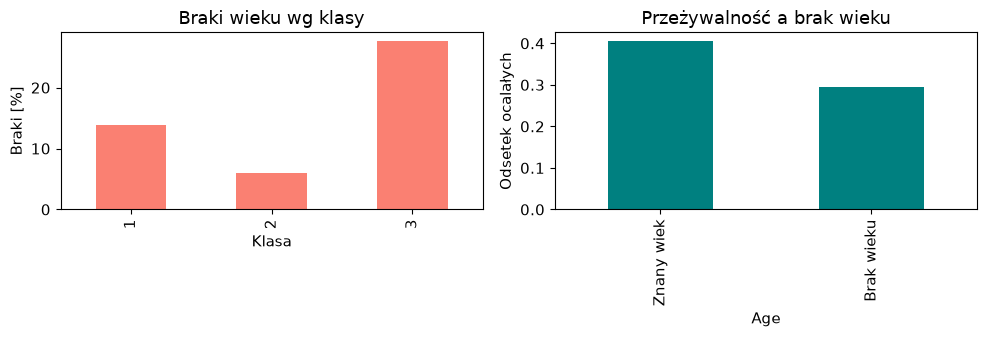

In [9]:
brak_wieku = titanic["Age"].isna()

# 2. Braki wg klasy i płci
print("Odsetek braków wieku wg klasy [%]:")
print((brak_wieku.groupby(titanic['Pclass']).mean() * 100).round(2))

print("\nOdsetek braków wieku wg płci [%]:")
print((brak_wieku.groupby(titanic['Sex']).mean() * 100).round(2))

# 3. Przeżywalność ze znanym wiekiem i bez
print("\nOdsetek ocalałych:")
print(f"Ze znanym wiekiem: {titanic.loc[~brak_wieku, 'Survived'].mean() * 100:.2f}%")
print(f"Bez podanego wieku: {titanic.loc[brak_wieku, 'Survived'].mean() * 100:.2f}%")

# 4. Wykresy
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
(brak_wieku.groupby(titanic['Pclass']).mean() * 100).plot.bar(ax=axes[0], color='salmon')
axes[0].set_title("Braki wieku wg klasy")
axes[0].set_xlabel("Klasa")
axes[0].set_ylabel("Braki [%]")

titanic.groupby(brak_wieku)['Survived'].mean().rename({False: 'Znany wiek', True: 'Brak wieku'}).plot.bar(ax=axes[1], color='teal')
axes[1].set_title("Przeżywalność a brak wieku")
axes[1].set_ylabel("Odsetek ocalałych")
plt.tight_layout()
plt.show()


*Twoja odpowiedź:*

Braki wieku to nie jest MCAR, lecz MAR – brak zależy od klasy (w 3. klasie brakuje wieku u prawie 29% osób, a w 1. klasie tylko u ok. 14%). Osoby bez wieku miały wyraźnie niższą przeżywalność (ok. 29% vs 40%). Usunięcie wierszy bez wieku sztucznie zawyżyłoby ogólny odsetek ocalałych i zafałszowało strukturę klas.


### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [12]:
warianty = {
    "bez zmian": titanic,
    "dropna(Embarked)": titanic.dropna(subset=["Embarked"]),
    "dropna(Age)": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna()
}

wyniki = []
for nazwa, df_w in warianty.items():
    wyniki.append({
        "wariant": nazwa,
        "liczba_wierszy": len(df_w),
        "ocali [%]": round(df_w['Survived'].mean() * 100, 2),
        "1_klasa [%]": round((df_w['Pclass'] == 1).mean() * 100, 2)
    })

tabela_warianty = pd.DataFrame(wyniki).set_index("wariant")
display(tabela_warianty)


,liczba_wierszy,ocali [%],1_klasa [%]
wariant,,,
bez zmian,891,38.38,24.24
dropna(Embarked),889,38.25,24.07
dropna(Age),714,40.62,26.05
dropna(),183,67.21,86.34


*Twoja odpowiedź:*

Najbardziej dane zniekształca wariant pełnego `dropna()` – zostaje tylko 183 z 891 pasażerów (tracimy prawie 80% zbioru!), a udział 1. klasy rośnie z 24% aż do prawie 86%, bo kabinę odnotowywano głównie u najbogatszych.


### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Odchylenie standardowe znane: 14.53
Odchylenie standardowe po średniej: 13.00
Odchylenie standardowe po grupach: 13.30


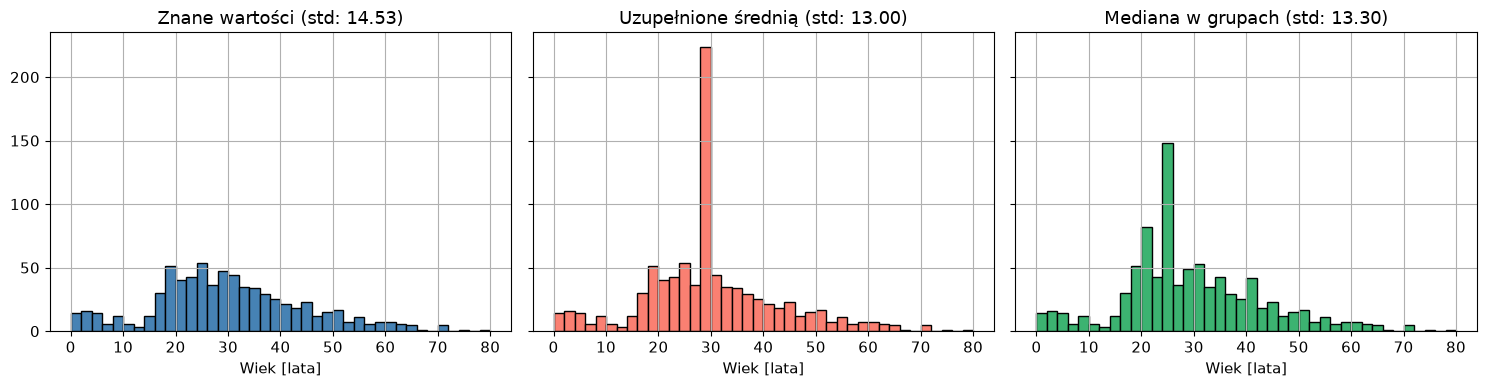

In [15]:
titanic_imp = titanic.copy()
titanic_imp['Age_brak'] = titanic_imp['Age'].isna()

# Średnia
srednia = titanic_imp['Age'].mean()
titanic_imp['wiek_srednia'] = titanic_imp['Age'].fillna(srednia)

# Mediana w grupach Pclass x Sex
mediana_grup = titanic_imp.groupby(['Pclass', 'Sex'])['Age'].transform('median')
titanic_imp['wiek_grupy'] = titanic_imp['Age'].fillna(mediana_grup)

# Histogramy
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.arange(0, 82, 2)

titanic_imp['Age'].dropna().hist(bins=bins, ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title(f"Znane wartości (std: {titanic_imp['Age'].std():.2f})")
axes[0].set_xlabel("Wiek [lata]")

titanic_imp['wiek_srednia'].hist(bins=bins, ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title(f"Uzupełnione średnią (std: {titanic_imp['wiek_srednia'].std():.2f})")
axes[1].set_xlabel("Wiek [lata]")

titanic_imp['wiek_grupy'].hist(bins=bins, ax=axes[2], color='mediumseagreen', edgecolor='black')
axes[2].set_title(f"Mediana w grupach (std: {titanic_imp['wiek_grupy'].std():.2f})")
axes[2].set_xlabel("Wiek [lata]")

plt.tight_layout()
plt.show()

print(f"Odchylenie standardowe znane: {titanic_imp['Age'].std():.2f}")
print(f"Odchylenie standardowe po średniej: {titanic_imp['wiek_srednia'].std():.2f}")
print(f"Odchylenie standardowe po grupach: {titanic_imp['wiek_grupy'].std():.2f}")


*Twoja odpowiedź:*

Uzupełnienie zwykłą średnią całościową bardziej zniekształca rozkład – na wykresie tworzy wielką, sztuczną szpilkę w okolicy 29.7 lat i obniża odchylenie standardowe (z 14.5 do 13.0). Mediana w grupach zachowuje naturalniejszy kształt rozkładu.


### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

Std po IterativeImputer: 13.64


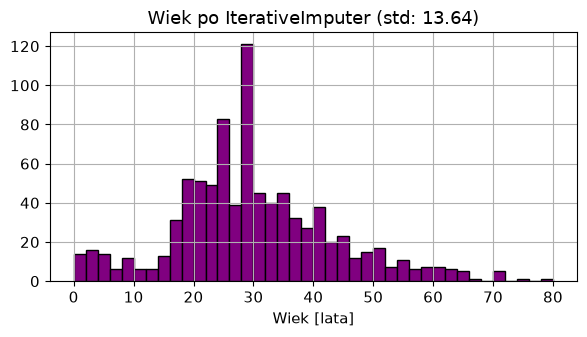

In [18]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

cechy = ['Pclass', 'SibSp', 'Parch', 'Fare', 'Age']
X_imp = titanic[cechy].copy()
X_imp['Sex_male'] = (titanic['Sex'] == 'male').astype(int)

imputer = IterativeImputer(random_state=42)
X_imputed = imputer.fit_transform(X_imp)
wiek_model = pd.Series(X_imputed[:, 4], index=titanic.index)

print(f"Std po IterativeImputer: {wiek_model.std():.2f}")

plt.figure(figsize=(6, 3.5))
wiek_model.hist(bins=bins, color='purple', edgecolor='black')
plt.title(f"Wiek po IterativeImputer (std: {wiek_model.std():.2f})")
plt.xlabel("Wiek [lata]")
plt.tight_layout()
plt.show()


---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [21]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print("Typy kolumn (dtypes):")
print(mieszkania.dtypes)

print("\nLiczba braków wykryta przez pandas:")
print(mieszkania.isna().sum())


Typy kolumn (dtypes):
id               int64
miasto             str
dzielnica          str
powierzchnia       str
liczba_pokoi     int64
rok_budowy         str
pietro             str
liczba_pieter    int64
parking            str
balkon             str
stan               str
cena_m2          int64
cena_total       int64
dtype: object

Liczba braków wykryta przez pandas:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


*Twoja odpowiedź:*

Pandas widzi braki tylko w kolumnach `powierzchnia` (4) i `rok_budowy` (4). Kolumna `powierzchnia` ma typ `object` (napisowy), ponieważ zawiera tekstowe oznaczenia braków typu `'brak'` oraz `'0'`, przez co pandas nie mógł potraktować jej jako liczby.


### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [24]:
# Przegląd unikalnych wartości w kolumnach
for kol in ['powierzchnia', 'rok_budowy', 'pietro', 'parking', 'balkon', 'stan']:
    print(f"Kolumna {kol}:", mieszkania[kol].unique())


Kolumna powierzchnia: <StringArray>
[  '65',   '48',   '72',   '55',   '80',    nan,   '60',   '45',   '70',
   '90',   '58',   '52',   '68',    '0',   '75',   '62',   '50', 'brak',
   '66',   '85',   '54',   '95',   '56',   '42',   '78',   '88',   '64',
   '51',   '69',   '46',   '82',   '76']
Length: 32, dtype: str
Kolumna rok_budowy: <StringArray>
['2015',    nan, '2010', '2018', '1998', '2020', '2005', '2019', 'brak',
 '2001', '2016', '1995', '2012', '2017', '2014', '2008', '2011', '1999',
 '2003', '2013', '2009', '2021', '1997', '2007', '2002', '1996', '2006',
 '2022', '2000', '2004']
Length: 30, dtype: str
Kolumna pietro: <StringArray>
['4', '2', 'brak', '3', '1', '7', '0', '5', '-999', '6', '8']
Length: 11, dtype: str
Kolumna parking: <StringArray>
['Tak', 'Nie', '?']
Length: 3, dtype: str
Kolumna balkon: <StringArray>
['Tak', 'Nie', '?']
Length: 3, dtype: str
Kolumna stan: <StringArray>
['Dobry', '很好', 'Bardzo dobry', 'Do remontu']
Length: 4, dtype: str


*Twoja odpowiedź:*

Wartości oznaczające brak: w `powierzchnia`: `'brak'`, `'0'`; w `rok_budowy`: `'brak'`; w `pietro`: `'brak'`, `'-999'`; w `parking` i `balkon`: `'?'`. Wartość `0` w `powierzchnia` to brak (mieszkanie nie może mieć 0 m²), ale w `pietro` oznacza po prostu parter (więc nie jest to brak!).


In [26]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("Typy kolumn po na_values:")
print(mieszkania.dtypes)

print("\nRzeczywista liczba braków:")
print(mieszkania.isna().sum())


Typy kolumn po na_values:
id                 int64
miasto               str
dzielnica            str
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking              str
balkon               str
stan                 str
cena_m2            int64
cena_total         int64
dtype: object

Rzeczywista liczba braków:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          0
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [28]:
print("Wartości w 'stan' przed:")
print(mieszkania['stan'].value_counts())

# Zamiana chińskiego '很好' na 'Bardzo dobry'
mieszkania['stan'] = mieszkania['stan'].replace({'很好': 'Bardzo dobry'})

print("\nWartości w 'stan' po poprawce:")
print(mieszkania['stan'].value_counts())
# '很好' (hěn hǎo) po chińsku oznacza 'bardzo dobry', więc pasuje do kategorii 'Bardzo dobry'.


Wartości w 'stan' przed:
stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64

Wartości w 'stan' po poprawce:
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

Korelacja występowania braków:


,powierzchnia,rok_budowy,pietro,parking,balkon
powierzchnia,1.000000e+00,-0.214599,-0.133631,-4.170558e-17,-0.133631
rok_budowy,-2.145988e-01,1.000000,-0.114708,4.335550e-02,0.131095
pietro,-1.336306e-01,-0.114708,1.000000,-9.449112e-02,-0.071429
parking,-4.170558e-17,0.043355,-0.094491,1.000000e+00,-0.094491
balkon,-1.336306e-01,0.131095,-0.071429,-9.449112e-02,1.000000


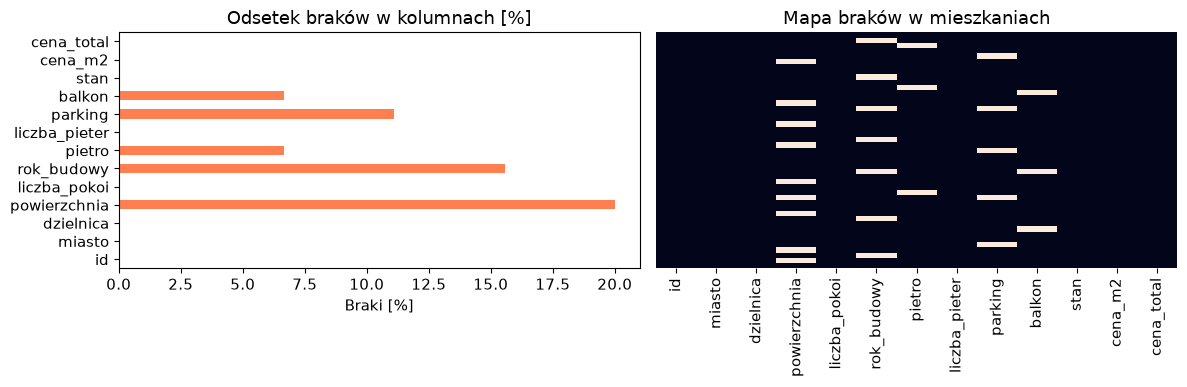

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

(mieszkania.isna().mean() * 100).plot.barh(ax=axes[0], color='coral')
axes[0].set_title("Odsetek braków w kolumnach [%]")
axes[0].set_xlabel("Braki [%]")

sns.heatmap(mieszkania.isna(), cbar=False, ax=axes[1], yticklabels=False)
axes[1].set_title("Mapa braków w mieszkaniach")
plt.tight_layout()
plt.show()

kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()]
print("Korelacja występowania braków:")
display(mieszkania[kolumny_z_brakami].isna().corr())


*Twoja odpowiedź:*

Braki nie są skoncentrowane w tych samych wierszach – korelacje między brakami są niskie (bliskie 0). Oznacza to, że nie mamy wierszy całkowicie zepsutych, lecz pojedyncze brakujące pola w różnych ofertach.


### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [33]:
# Sprawdzenie wzoru cena_total = powierzchnia * cena_m2
znane = mieszkania['powierzchnia'].notna()
zgadza_sie = np.isclose(mieszkania.loc[znane, 'powierzchnia'] * mieszkania.loc[znane, 'cena_m2'], mieszkania.loc[znane, 'cena_total'])
print("Czy zależność zachodzi w 100% znanych wierszy?", zgadza_sie.all())

# Odtworzenie powierzchni
brak_pow = mieszkania['powierzchnia'].isna()
ile_brakow_przed = brak_pow.sum()
mieszkania.loc[brak_pow, 'powierzchnia'] = mieszkania.loc[brak_pow, 'cena_total'] / mieszkania.loc[brak_pow, 'cena_m2']

print(f"Odtworzono {ile_brakow_przed} brakujących powierzchni. Pozostało braków: {mieszkania['powierzchnia'].isna().sum()}")


Czy zależność zachodzi w 100% znanych wierszy? False
Odtworzono 9 brakujących powierzchni. Pozostało braków: 0


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [35]:
# 1. Flagi braków
for k in ['rok_budowy', 'pietro', 'parking', 'balkon']:
    mieszkania[f"{k}_brak"] = mieszkania[k].isna()

# Sprawdzenie median dla roku budowy
print("Mediany roku budowy wg miasta:")
print(mieszkania.groupby('miasto')['rok_budowy'].median())
print("\nMediany roku budowy wg stanu:")
print(mieszkania.groupby('stan')['rok_budowy'].median())

# 2. Uzupełnienie:
# rok_budowy uzupełniamy medianą wg stanu (lepiej różnicuje wiek niż miasto)
mieszkania['rok_budowy'] = mieszkania['rok_budowy'].fillna(mieszkania.groupby('stan')['rok_budowy'].transform('median'))

# pietro uzupełniamy środkowym piętrem budynku
mieszkania['pietro'] = mieszkania['pietro'].fillna(mieszkania['liczba_pieter'] // 2)

# parking i balkon uzupełniamy 'Nie' (ostrożne założenie braku udogodnienia)
mieszkania['parking'] = mieszkania['parking'].fillna('Nie')
mieszkania['balkon'] = mieszkania['balkon'].fillna('Nie')

# 3. Sprawdzenie
kolumny_glowne = [c for c in mieszkania.columns if not c.endswith('_brak')]
print("\nLiczba braków po uzupełnieniu:")
print(mieszkania[kolumny_glowne].isna().sum())


Mediany roku budowy wg miasta:
miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64

Mediany roku budowy wg stanu:
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64

Liczba braków po uzupełnieniu:
id               0
miasto           0
dzielnica        0
powierzchnia     0
liczba_pokoi     0
rok_budowy       0
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

Statystyki PRZED uzupełnieniem:

Statystyki PO uzupełnieniu:


,powierzchnia,rok_budowy,cena_m2
count,36.000000,38.000000,45.000000
mean,64.638889,2010.289474,9746.666667
std,13.684512,7.828941,2735.914348
min,42.000000,1995.000000,-999.000000
25%,54.750000,2004.250000,8900.000000
50%,63.000000,2011.500000,9700.000000
75%,72.750000,2016.750000,11000.000000
max,95.000000,2022.000000,15000.000000


,powierzchnia,rok_budowy,cena_m2
count,45.000000,45.000000,45.000000
mean,64.933333,2010.644444,9746.666667
std,12.755391,7.407476,2735.914348
min,42.000000,1995.000000,-999.000000
25%,56.000000,2006.000000,8900.000000
50%,62.000000,2011.000000,9700.000000
75%,72.000000,2017.000000,11000.000000
max,95.000000,2022.000000,15000.000000


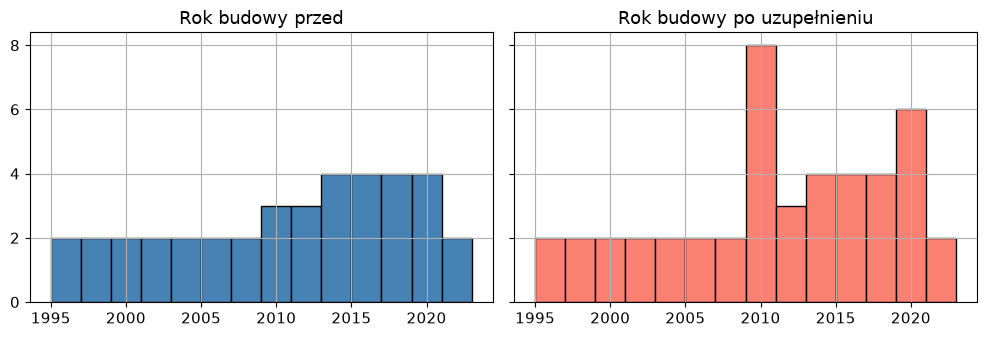

In [37]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("Statystyki PRZED uzupełnieniem:")
display(surowe[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

print("\nStatystyki PO uzupełnieniu:")
display(mieszkania[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

# Histogram roku budowy
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
bins_rok = np.arange(1995, 2025, 2)
surowe['rok_budowy'].dropna().hist(bins=bins_rok, ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title("Rok budowy przed")

mieszkania['rok_budowy'].hist(bins=bins_rok, ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title("Rok budowy po uzupełnieniu")
plt.tight_layout()
plt.show()


*Twoja odpowiedź:*

Uzupełnianie nie zmieniło rozkładów w istotny sposób – średnia powierzchnia i cena za m² pozostały niemal identyczne (powierzchnię odtworzyliśmy dokładnie ze wzoru matematycznego). Rozkład roku budowy zachował swój pierwotny kształt, ponieważ użyliśmy mediany powiązanej ze stanem technicznym zamiast płaskiej stałej.


### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `brak`, `0`, `NaN` | 9 | odtworzenie ze wzoru | `cena_total / cena_m2` daje dokładną, prawdziwą wartość bez zgadywania |
| `cena_m2` | brak braków | 0 | brak akcji | kolumna kompletna |
| `rok_budowy` | `brak`, `NaN` | 5 | mediana wg `stan` | stan lokalu silnie różnicuje wiek budynku (np. do remontu ok. 1998 r., bardzo dobry ok. 2018 r.) |
| `pietro` | `brak`, `-999` | 3 | `liczba_pieter // 2` | środkowe piętro budynku to rozsądne przybliżenie dla 3 braków |
| `parking` | `?` | 2 | uzupełnienie `'Nie'` | bezpieczne założenie braku udogodnienia, gdy nie zostało wpisane w ofercie |
| `balkon` | `?` | 2 | uzupełnienie `'Nie'` | bezpieczne założenie braku udogodnienia |
| `stan` | `很好` | 1 | zamiana na `'Bardzo dobry'` | dosłowne tłumaczenie z chińskiego pasujące do kategorii w kolumnie |


### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [41]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
znane = surowe.dropna(subset=['rok_budowy'])
corr_orig = znane['rok_budowy'].corr(znane['cena_m2'])

# 1. Mediana całościowa
r_calosc = surowe['rok_budowy'].fillna(surowe['rok_budowy'].median())
corr_calosc = r_calosc.corr(surowe['cena_m2'])

# 2. Mediana wg miasta
r_miasto = surowe['rok_budowy'].fillna(surowe.groupby('miasto')['rok_budowy'].transform('median'))
corr_miasto = r_miasto.corr(surowe['cena_m2'])

# 3. Mediana wg stanu
r_stan = surowe['rok_budowy'].fillna(surowe.groupby('stan')['rok_budowy'].transform('median'))
corr_stan = r_stan.corr(surowe['cena_m2'])

print(f"Korelacja w danych znanych: {corr_orig:.4f}")
print(f"Mediana całościowa:         {corr_calosc:.4f} (różnica: {abs(corr_calosc - corr_orig):.4f})")
print(f"Mediana wg miasta:          {corr_miasto:.4f} (różnica: {abs(corr_miasto - corr_orig):.4f})")
print(f"Mediana wg stanu:           {corr_stan:.4f} (różnica: {abs(corr_stan - corr_orig):.4f})")


Korelacja w danych znanych: 0.3722
Mediana całościowa:         0.3702 (różnica: 0.0020)
Mediana wg miasta:          0.3911 (różnica: 0.0189)
Mediana wg stanu:           0.3884 (różnica: 0.0162)


*Twoja odpowiedź:*

Mediana w grupach według stanu najmniej zmienia korelację w porównaniu z oryginalnymi danymi bez braków. Stan techniczny lokalu ściśle wiąże się zarówno z rokiem budowy, jak i z ceną za metr kwadratowy, więc uzupełnienie w ten sposób zachowuje istniejącą w danych strukturę powiązań.
